# 5.5 Hypothesis Testing

**Goal:** formulate tests and interpret p-values as sampling probabilities under a null model.

**Prerequisites:** Modules 0–4 and earlier notebooks in this module; advanced notebooks also build on earlier modules 5–8. Read the section assumptions before using a method.

**Runtime:** Python 3.10+ with NumPy, SciPy, and Matplotlib. Install in your chosen environment with `python3 -m pip install numpy scipy matplotlib`, then open in JupyterLab or VS Code with a Python kernel. Use **Restart Kernel and Run All**. Each notebook is self-contained, includes saved outputs, uses synthetic data and a fixed local random seed, and needs no downloads. Numerical simulations illustrate results; they do not prove them or validate real-world assumptions.

## Module navigation

1. [Sampling Techniques](1_Sampling-Techniques.ipynb)
2. [Sampling Concepts](2_Sampling-Concepts.ipynb)
3. [Estimation Theory](3_Estimation-Theory.ipynb)
4. [Confidence Intervals](4_Confidence-Intervals.ipynb)
5. [Hypothesis Testing](5_Hypothesis-Testing.ipynb)
6. [Statistical Errors](6_Statistical-Errors.ipynb)
7. [Statistical Tests](7_Statistical-Tests.ipynb)

## Learning route

Read each definition and assumption, work through its calculation, run the code, then attempt the practice before viewing the solutions. Distinguish descriptive association, causal inference, and predictive evaluation throughout.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, optimize, special, linalg
rng = np.random.default_rng(2026)
plt.rcParams.update({"figure.figsize": (7, 4), "axes.titlesize": 12, "font.size": 10})

## 1. Null Hypothesis (H0) and Alternative Hypothesis (H1)

The null specifies a reference claim and sampling model; the alternative specifies the departure of interest. For a mean difference Δ, a two-sided test may use H₀:Δ=0 versus H₁:Δ≠0. A directional superiority question might use H₀:Δ≤0 versus H₁:Δ>0, calibrated at the boundary Δ=0 under suitable monotonicity. State the population, estimand, design, and direction before seeing the outcome.

A statistical hypothesis is not a complete scientific theory. Rejecting a null can also reflect violated assumptions or bias. Failing to reject does not prove equality; equivalence and noninferiority require explicit margins and their own procedures.

## 2. Test Statistic and Critical Value

A test statistic compresses the discrepancy into a quantity with a known or approximated null distribution. For an IID normal mean with known σ,
$$Z=(\bar X-\mu_0)/(\sigma/\sqrt n).$$
Unknown σ leads to a t statistic with n−1 degrees of freedom under normal sampling. A **critical value** marks a rejection region calibrated under H₀. A two-sided z test at α=.05 rejects if |Z|>1.959964; a predeclared greater-than test uses Z>1.644854.

**Worked example:** observed mean 102, null 100, known σ=10 and n=100 gives z=2. The standard error is 1, not 10.

In [2]:
z=(102-100)/(10/np.sqrt(100))
print("z:",z,"two-sided critical value:",stats.norm.ppf(.975))

z: 2.0 two-sided critical value: 1.959963984540054


## 3. Significance Level (Alpha) and P-value

α bounds a test procedure's Type I error probability under its null assumptions. A p-value is the probability, under the specified null model, of a test statistic at least as incompatible with the null as observed, using the chosen ordering/tails. It is **not** P(H₀ is true), the probability results happened “by chance,” an effect magnitude, or a replication probability.

For a continuous standard-normal statistic, a two-sided p-value is 2Φ(−|z|). The greater-tail p-value is 1−Φ(z). These definitions must match the planned alternative. Discrete tests may be conservative because not every nominal rejection probability is attainable.

**Example:** z=2 gives two-sided p≈.0455 and greater-tail p≈.02275. Halving a two-sided result after inspecting its direction is not a preplanned one-sided test.

In [3]:
print("Two-sided p:",2*stats.norm.sf(abs(z)))
print("Greater-tail p:",stats.norm.sf(z))
print("Less-tail p:",stats.norm.cdf(z))
assert np.isclose(stats.norm.sf(z)+stats.norm.cdf(z),1)

Two-sided p: 0.045500263896358396
Greater-tail p: 0.022750131948179198
Less-tail p: 0.9772498680518208


## 4. One-tailed Test and Two-tailed Test

A one-tailed test allocates rejection probability to the prespecified direction, potentially improving power there while not supporting the opposite directional claim. A two-tailed test considers both directions. Scientific risks and the decision determine the alternative; observed sign does not.

For compatible methods, a two-sided level-α test rejects a point null exactly when the corresponding (1−α) confidence interval excludes that value. This duality is method-specific: a Wilson interval and an unrelated Wald test need not agree.

Sequential peeking with a fixed-horizon p-value can inflate false positives. Choose a fixed stopping rule or a valid sequential design. Report estimates, uncertainty, sample sizes, analysis choices, and practical consequences, including nonsignificant results.

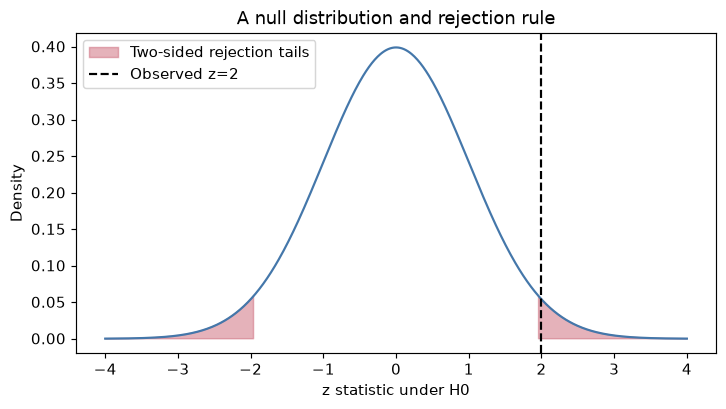

In [4]:
grid=np.linspace(-4,4,601);critical=stats.norm.ppf(.975)
fig,ax=plt.subplots()
ax.plot(grid,stats.norm.pdf(grid),color="#4477AA")
ax.fill_between(grid,stats.norm.pdf(grid),where=np.abs(grid)>=critical,color="#CC6677",alpha=.5,label="Two-sided rejection tails")
ax.axvline(z,color="black",linestyle="--",label="Observed z=2")
ax.set(title="A null distribution and rejection rule",xlabel="z statistic under H0",ylabel="Density")
ax.legend();fig.tight_layout();plt.show()

## AI/ML application and interpretation

Feature significance is conditional on the tested model and analysis pipeline. Trying many feature transformations and reporting only the smallest p-value requires accounting for selection. For model comparisons, a significant average difference does not establish a practically useful improvement or robust deployment performance.

## Practice

1. Does p=.03 mean a 3% chance that H₀ is true?
2. Can p=.4 prove there is no meaningful effect?
3. With z=−2, which tail gives evidence for a greater-than alternative?
4. Why is choosing the alternative after seeing the result problematic?
5. What additional information should accompany a small p-value?

## Solutions

1. No. It is a tail probability of a statistic under the null model, not a posterior probability of a hypothesis.
2. No. The study may have low power or a wide uncertainty interval; an equivalence claim needs a prespecified meaningful margin.
3. The greater-tail p is about .97725, providing little evidence for that direction. The observed sign favors the opposite direction.
4. It adds an unaccounted selection step and changes the procedure's error control.
5. Effect size, interval, independent sample size, design, assumptions, multiplicity/stopping choices, and practical implications.

**Readiness check:** identify the estimand, independent unit, assumptions, uncertainty source, and an important failure mode before using these methods.

**Next:** [Continue studying](6_Statistical-Errors.ipynb).